# The Pacemaker of the Ice Ages — an End-to-End Machine Learning Project

This notebook contains all the code of the guide `index.html` (same folder).
Every figure of the guide is produced here and saved in `images/`.

**Data (real):** EPICA Dome C ice-core temperature (800,000 years), the Antarctic CO2
composite, the LR04 deep-sea benthic δ18O stack (5.3 million years), and the La2004
astronomical solution for the Earth's orbit (Laskar et al. 2004).

## Setup

In [1]:
# Python ≥3.8 is required
import sys
assert sys.version_info >= (3, 8)

# Scikit-Learn ≥1.0 is required
import sklearn
assert sklearn.__version__ >= "1.0"

# Common imports
import os
import numpy as np
import pandas as pd

# To make this notebook's output stable across runs
np.random.seed(42)

# To plot pretty figures
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=13)
mpl.rc('xtick', labelsize=11)
mpl.rc('ytick', labelsize=11)

# Where to save the figures
PROJECT_ROOT_DIR = "."
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images")
os.makedirs(IMAGES_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=150):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

## Get the Data

In [2]:
import urllib.request

DATA_PATH = os.path.join("datasets")
NOAA = "https://www.ncei.noaa.gov/pub/data/paleo/"
SOURCES = {
    "epica_temperature.txt": NOAA + "icecore/antarctica/epica_domec/edc3deuttemp2007.txt",
    "antarctic_co2_composite.txt": NOAA + "icecore/antarctica/antarctica2015co2composite.txt",
    "lr04_benthic_stack.txt": NOAA + "contributions_by_author/lisiecki2005/lisiecki2005.txt",
    "La2004_past.txt": "https://vo.imcce.fr/insola/earth/online/earth/La2004/INSOLN.LA2004.BTL.ASC",
    "La2004_future.txt": "https://vo.imcce.fr/insola/earth/online/earth/La2004/INSOLP.LA2004.BTL.ASC",
}

def fetch_paleo_data(path=DATA_PATH):
    os.makedirs(path, exist_ok=True)
    for name, url in SOURCES.items():
        target = os.path.join(path, name)
        if os.path.exists(target):
            continue
        text = urllib.request.urlopen(url, timeout=300).read().decode("latin-1")
        if name.startswith("La2004"):        # keep -6 Myr .. +1 Myr (the files go to -51 Myr)
            lines = [l for l in text.splitlines() if l.strip() and abs(float(l.split()[0])) <= 6000]
            text = "\n".join(lines) + "\n"
        with open(target, "w") as f:
            f.write(text)

fetch_paleo_data()
sorted(os.listdir(DATA_PATH))

['La2004_future.txt',
 'La2004_past.txt',
 'antarctic_co2_composite.txt',
 'epica_temperature.txt',
 'lr04_benthic_stack.txt']

In [3]:
def load_epica(path=DATA_PATH):
    df = pd.read_csv(os.path.join(path, "epica_temperature.txt"), sep=r"\s+", skiprows=91,
                     names=["bag", "depth_m", "age_yr", "deuterium", "temperature"], header=0)
    df = df.dropna()
    df = df[df["age_yr"] > 0]
    return df.assign(age_kyr=df["age_yr"] / 1000)

def load_orbit(path=DATA_PATH):
    """La2004: time (kyr, negative = past), eccentricity, obliquity (rad),
    longitude of perihelion from the moving equinox (rad)."""
    frames = []
    for name in ("La2004_past.txt", "La2004_future.txt"):
        d = pd.read_csv(os.path.join(path, name), sep=r"\s+", header=None,
                        names=["t_kyr", "ecc", "obliquity", "varpi"], dtype=str)
        frames.append(d.apply(lambda col: col.str.replace("D", "E").astype(float)))
    orbit = pd.concat(frames).drop_duplicates("t_kyr").sort_values("t_kyr").reset_index(drop=True)
    return orbit

def load_co2(path=DATA_PATH):
    lines = open(os.path.join(path, "antarctic_co2_composite.txt"), encoding="latin-1").read().splitlines()
    start = next(i for i, l in enumerate(lines) if l.startswith("age_gas_calBP"))
    rows = [l.split() for l in lines[start + 1:] if len(l.split()) == 3]
    co2 = pd.DataFrame(rows, columns=["age_yr", "co2_ppm", "co2_err"]).astype(float)
    return co2.assign(age_kyr=co2["age_yr"] / 1000)

def load_lr04(path=DATA_PATH):
    lines = open(os.path.join(path, "lr04_benthic_stack.txt"), encoding="latin-1").read().splitlines()
    rows = []
    for l in lines:
        parts = l.split()
        if len(parts) == 3:
            try:
                row = [float(p) for p in parts]
            except ValueError:
                continue
            if rows and row[0] < rows[-1][0]:      # the file holds other tables after the stack
                break
            rows.append(row)
    return pd.DataFrame(rows, columns=["age_kyr", "d18O", "d18O_err"])

epica, orbit, co2, lr04 = load_epica(), load_orbit(), load_co2(), load_lr04()
epica.head()

,bag,depth_m,age_yr,deuterium,temperature,age_kyr
12,13,6.60,38.37379,-390.9,0.88,0.038374
13,14,7.15,46.81203,-385.1,1.84,0.046812
14,15,7.70,55.05624,-377.8,3.04,0.055056
15,16,8.25,64.41511,-394.1,0.35,0.064415
16,17,8.80,73.15077,-398.7,-0.42,0.073151


In [4]:
epica.info()

<class 'pandas.DataFrame'>
Index: 5785 entries, 12 to 5799
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   bag          5785 non-null   int64  
 1   depth_m      5785 non-null   float64
 2   age_yr       5785 non-null   float64
 3   deuterium    5785 non-null   float64
 4   temperature  5785 non-null   float64
 5   age_kyr      5785 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 316.4 KB


In [5]:
epica[["age_kyr", "deuterium", "temperature"]].describe().round(2)

,age_kyr,deuterium,temperature
count,5785.00,5785.0,5785.00
mean,190.51,-417.8,-4.58
std,192.55,18.0,3.45
min,0.04,-449.5,-10.58
25%,46.79,-432.5,-7.45
50%,122.11,-421.3,-5.20
75%,273.34,-403.3,-1.82
max,801.66,-361.2,5.46


In [6]:
orbit[(orbit["t_kyr"] >= -2) & (orbit["t_kyr"] <= 2)]

,t_kyr,ecc,obliquity,varpi
5998,-2.0,0.017497,0.413555,1.200024
5999,-1.0,0.017161,0.411353,1.497928
6000,0.0,0.016702,0.409093,1.796257
6001,1.0,0.016275,0.406834,2.098561
6002,2.0,0.015850,0.404631,2.397657


In [7]:
spacing = np.diff(epica["age_kyr"].values)
print(f"median spacing: {np.median(spacing[epica['age_kyr'].values[1:] < 10]) * 1000:.0f} years "
      f"(last 10 kyr) vs {np.median(spacing[epica['age_kyr'].values[1:] > 700]) * 1000:.0f} years (> 700 kyr)")

median spacing: 19 years (last 10 kyr) vs 621 years (> 700 kyr)


## Create a Test Set

In [8]:
# Uneven sampling -> one value per 1,000 years (interpolation), so that every epoch
# weighs the same in the error
ages = np.arange(0, 800)                             # kyr before present
temp = np.interp(ages, epica["age_kyr"], epica["temperature"])
climate = pd.DataFrame({"age_kyr": ages, "temperature": temp})
# Time-series split: the most recent glacial cycle is the test set (the "future")
TEST_AGE = 130
train_set = climate[climate["age_kyr"] >= TEST_AGE].copy()
test_set = climate[climate["age_kyr"] < TEST_AGE].copy()
len(train_set), len(test_set)

(670, 130)

## Discover and Visualize the Data to Gain Insights

Saving figure epica_temperature_plot


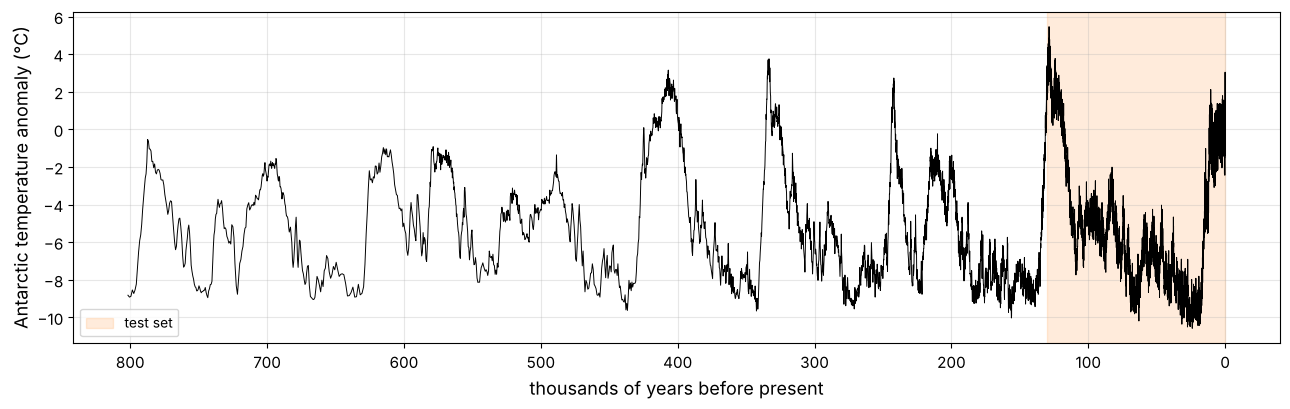

In [9]:
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(epica["age_kyr"], epica["temperature"], "k-", lw=0.7)
ax.axvspan(0, TEST_AGE, color="tab:orange", alpha=0.15, label="test set")
ax.invert_xaxis(); ax.set_xlabel("thousands of years before present")
ax.set_ylabel("Antarctic temperature anomaly (°C)"); ax.grid(alpha=0.3); ax.legend(loc="lower left")
save_fig("epica_temperature_plot")
plt.show()

Saving figure lr04_plot


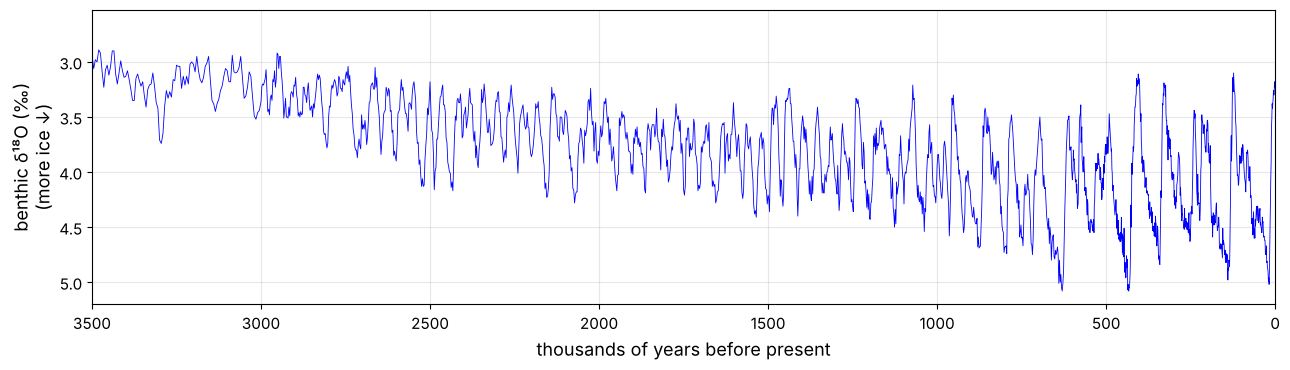

In [10]:
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(lr04["age_kyr"], lr04["d18O"], "b-", lw=0.6)
ax.invert_xaxis(); ax.invert_yaxis()
ax.set_xlabel("thousands of years before present"); ax.set_ylabel("benthic δ¹⁸O (‰)\n(more ice ↓)")
ax.set_xlim(3500, 0); ax.grid(alpha=0.3)
save_fig("lr04_plot")
plt.show()

In [11]:
co2_on_grid = np.interp(climate["age_kyr"], co2["age_kyr"], co2["co2_ppm"])
climate["co2_ppm"] = co2_on_grid
climate[["temperature", "co2_ppm"]].corr().round(3)

,temperature,co2_ppm
temperature,1.000,0.886
co2_ppm,0.886,1.000


Saving figure co2_temperature_plot


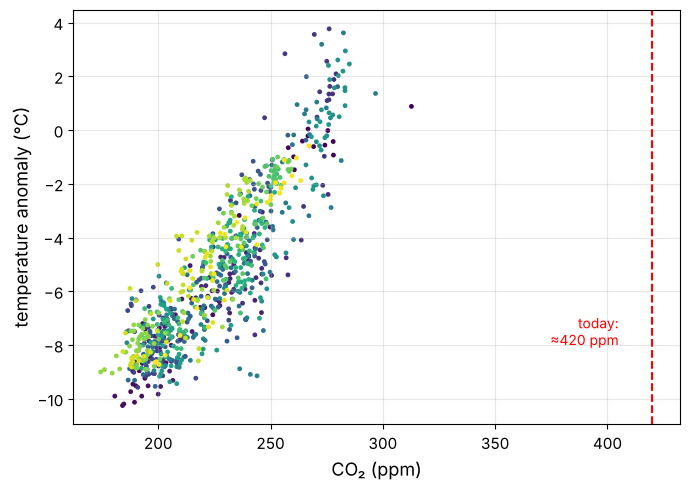

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(climate["co2_ppm"], climate["temperature"], s=6, c=climate["age_kyr"], cmap="viridis")
ax.axvline(420, color="r", ls="--"); ax.text(405, -8, "today:\n≈420 ppm", color="r", ha="right")
ax.set_xlabel("CO₂ (ppm)"); ax.set_ylabel("temperature anomaly (°C)"); ax.grid(alpha=0.3)
save_fig("co2_temperature_plot")
plt.show()

In [13]:
from scipy.signal import lombscargle, find_peaks

def periodogram(age, value, periods):
    return lombscargle(age, value - value.mean(), 2 * np.pi / periods, normalize=True)

periods = np.linspace(10, 150, 4000)
power = periodogram(epica["age_kyr"].values, epica["temperature"].values, periods)
peaks, _ = find_peaks(power, height=0.02, distance=60)
top = peaks[np.argsort(power[peaks])[::-1][:6]]
pd.DataFrame({"period_kyr": periods[top].round(1), "power": power[top].round(3)})

,period_kyr,power
0,40.5,0.309
1,101.8,0.261
2,114.6,0.261
3,139.9,0.195
4,64.5,0.176
5,57.1,0.135


Saving figure periodograms_plot


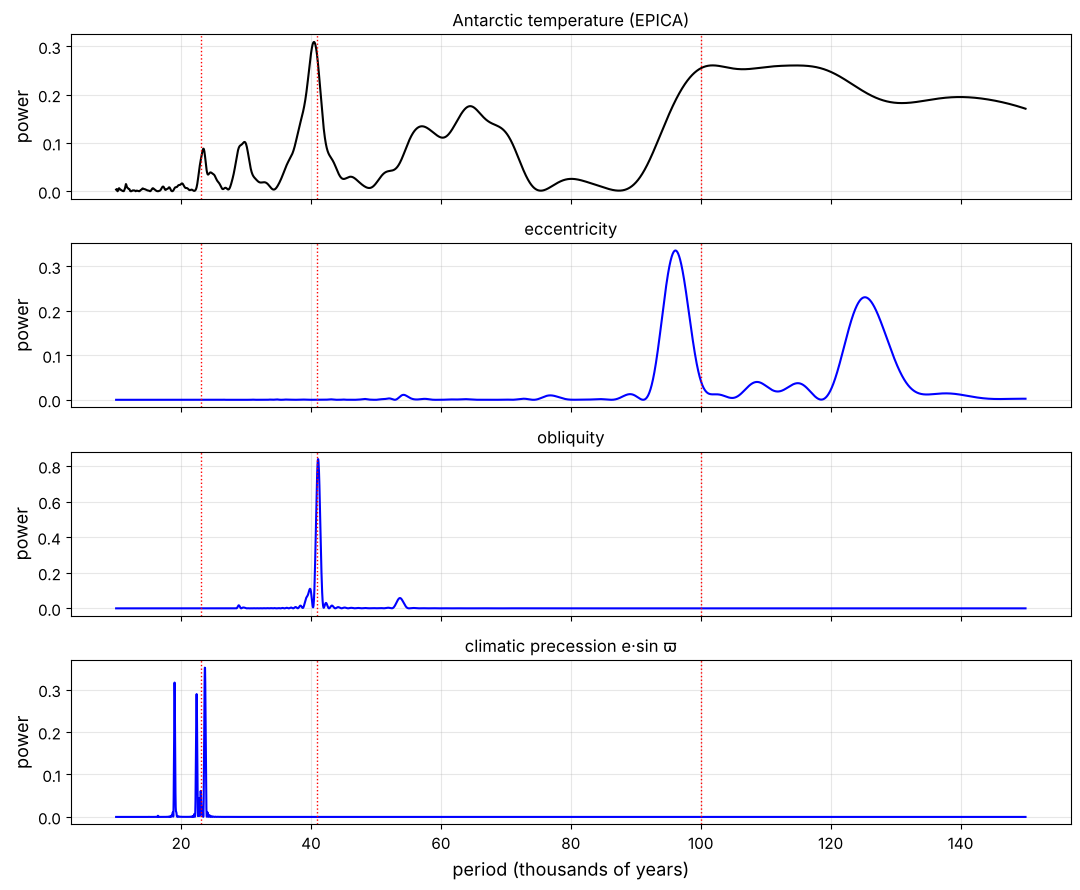

In [14]:
past = orbit[(orbit["t_kyr"] <= 0) & (orbit["t_kyr"] >= -2000)]
orbit_power = {
    "eccentricity": periodogram(-past["t_kyr"].values, past["ecc"].values, periods),
    "obliquity": periodogram(-past["t_kyr"].values, past["obliquity"].values, periods),
    "climatic precession e·sin ϖ": periodogram(-past["t_kyr"].values,
                                               (past["ecc"] * np.sin(past["varpi"])).values, periods),
}
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
axes[0].plot(periods, power, "k-"); axes[0].set_ylabel("power"); axes[0].set_title("Antarctic temperature (EPICA)")
for ax, (name, pw) in zip(axes[1:], orbit_power.items()):
    ax.plot(periods, pw, "b-"); ax.set_ylabel("power"); ax.set_title(name)
for ax in axes:
    for p in (23, 41, 100):
        ax.axvline(p, color="r", ls=":", lw=1)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("period (thousands of years)")
save_fig("periodograms_plot")
plt.show()

## Prepare the Data for Machine Learning Algorithms

In [15]:
S0 = 1361.0     # W/m², total solar irradiance

def daily_insolation(ecc, obliquity, varpi, latitude_deg=65.0, solar_longitude_deg=90.0):
    """Daily-mean top-of-atmosphere insolation (W/m²) at a latitude, on the day when the Sun
    is at a given longitude (90° = northern summer solstice). varpi as in La2004 (heliocentric)."""
    phi, lam = np.radians(latitude_deg), np.radians(solar_longitude_deg)
    delta = np.arcsin(np.sin(obliquity) * np.sin(lam))                 # solar declination
    h0 = np.arccos(np.clip(-np.tan(phi) * np.tan(delta), -1, 1))       # sunset hour angle
    distance_factor = (1 + ecc * np.cos(lam - varpi - np.pi)) / (1 - ecc ** 2)   # (a/r)
    return S0 / np.pi * distance_factor ** 2 * (h0 * np.sin(phi) * np.sin(delta) +
                                                np.cos(phi) * np.cos(delta) * np.sin(h0))

orbit["insolation_65N"] = daily_insolation(orbit["ecc"], orbit["obliquity"], orbit["varpi"])
now = orbit.loc[orbit["t_kyr"] == 0, "insolation_65N"].iloc[0]
last_myr = orbit[(orbit["t_kyr"] <= 0) & (orbit["t_kyr"] >= -1000)]["insolation_65N"]
print(f"65°N summer insolation today: {now:.1f} W/m²  (range over 1 Myr: {last_myr.min():.0f}–{last_myr.max():.0f})")

65°N summer insolation today: 477.9 W/m²  (range over 1 Myr: 431–559)


Saving figure insolation_plot


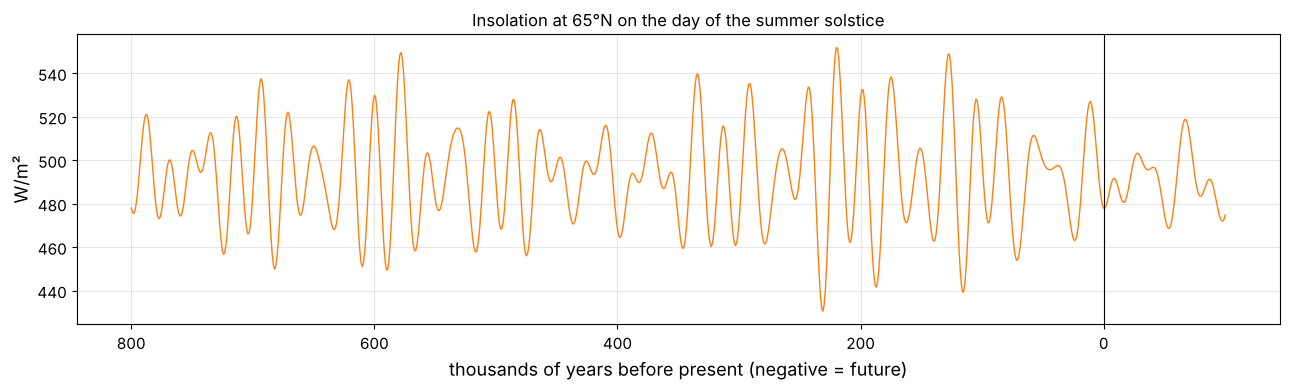

In [16]:
fig, ax = plt.subplots(figsize=(13, 4))
w = (orbit["t_kyr"] >= -800) & (orbit["t_kyr"] <= 100)
ax.plot(-orbit.loc[w, "t_kyr"], orbit.loc[w, "insolation_65N"], "tab:orange", lw=1)
ax.invert_xaxis(); ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("thousands of years before present (negative = future)"); ax.set_ylabel("W/m²")
ax.set_title("Insolation at 65°N on the day of the summer solstice"); ax.grid(alpha=0.3)
save_fig("insolation_plot")
plt.show()

In [17]:
from sklearn.base import BaseEstimator, TransformerMixin

class OrbitalFeatures(BaseEstimator, TransformerMixin):
    """age (kyr) -> orbital features at that time and at earlier times (lag features)."""
    def __init__(self, lags=(0, 5, 10, 20), latitude=65.0):
        self.lags = lags
        self.latitude = latitude
    def fit(self, X, y=None):
        return self
    def __sklearn_is_fitted__(self):
        return True
    def transform(self, X):
        age = np.asarray(X, dtype=float).ravel()
        t = orbit["t_kyr"].values
        ins = daily_insolation(orbit["ecc"], orbit["obliquity"], orbit["varpi"], self.latitude).values
        cols = []
        for lag in self.lags:
            ta = -(age + lag)
            e, eps, vp = (np.interp(ta, t, orbit[c].values) for c in ("ecc", "obliquity", "varpi_unwrapped"))
            cols += [np.interp(ta, t, ins), e, eps, e * np.sin(vp), e * np.cos(vp)]
        return np.column_stack(cols)

orbit["varpi_unwrapped"] = np.unwrap(orbit["varpi"].values)
OrbitalFeatures().fit_transform(train_set[["age_kyr"]])[:2].round(4)

array([[ 5.386247e+02,  3.940000e-02,  4.235000e-01, -2.820000e-02,
        -2.760000e-02,  4.862400e+02,  3.660000e-02,  4.198000e-01,
         1.920000e-02, -3.110000e-02,  4.627319e+02,  3.340000e-02,
         4.079000e-01,  3.170000e-02,  1.050000e-02,  5.049179e+02,
         2.840000e-02,  3.917000e-01, -2.790000e-02,  5.300000e-03],
       [ 5.296083e+02,  3.890000e-02,  4.237000e-01, -1.950000e-02,
        -3.370000e-02,  4.774026e+02,  3.580000e-02,  4.179000e-01,
         2.630000e-02, -2.440000e-02,  4.644205e+02,  3.270000e-02,
         4.051000e-01,  2.730000e-02,  1.810000e-02,  5.055683e+02,
         2.820000e-02,  3.922000e-01, -2.810000e-02, -1.900000e-03]])

## Select and Train a Model

In [18]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

X_train, y_train = train_set[["age_kyr"]], train_set["temperature"].values
lin_model = make_pipeline(OrbitalFeatures(), StandardScaler(), Ridge(alpha=1.0))
lin_model.fit(X_train, y_train)
pred = lin_model.predict(X_train)
print(f"linear model, training RMSE = {np.sqrt(mean_squared_error(y_train, pred)):.2f} °C, "
      f"correlation = {np.corrcoef(pred, y_train)[0, 1]:.2f}")

linear model, training RMSE = 1.85 °C, correlation = 0.75


In [19]:
from sklearn.model_selection import GroupKFold, cross_val_score

blocks = ((train_set["age_kyr"].values - TEST_AGE) // 134).astype(int)   # 5 blocks of ~134 kyr
blocked_cv = GroupKFold(n_splits=len(np.unique(blocks)))
def rmse_scores(model):
    return -cross_val_score(model, X_train, y_train, groups=blocks, cv=blocked_cv,
                            scoring="neg_root_mean_squared_error")
def display_scores(name, s):
    print(f"{name:28s} RMSE per block: {np.round(s, 2)}  mean {s.mean():.2f} °C")

display_scores("linear (orbit + lags)", rmse_scores(lin_model))

linear (orbit + lags)        RMSE per block: [1.53 1.92 2.76 2.31 1.87]  mean 2.08 °C


In [20]:
from sklearn.ensemble import HistGradientBoostingRegressor

gbm = make_pipeline(OrbitalFeatures(lags=tuple(range(0, 101, 5))),
                    HistGradientBoostingRegressor(max_iter=300, random_state=42))
display_scores("gradient boosting (21 lags)", rmse_scores(gbm))
gbm.fit(X_train, y_train)
print(f"gradient boosting training RMSE = {np.sqrt(mean_squared_error(y_train, gbm.predict(X_train))):.2f} °C")

gradient boosting (21 lags)  RMSE per block: [2.22 1.62 2.73 2.84 3.17]  mean 2.51 °C


gradient boosting training RMSE = 0.06 °C


In [21]:
lin_full = lin_model.predict(climate[["age_kyr"]])
p_lin = periodogram(climate["age_kyr"].values, lin_full, periods)
p_obs = periodogram(climate["age_kyr"].values, climate["temperature"].values, periods)
band = lambda p, lo, hi: p[(periods > lo) & (periods < hi)].max()
pd.DataFrame({"data": [band(p_obs, 19, 25), band(p_obs, 38, 44), band(p_obs, 80, 130)],
              "linear model": [band(p_lin, 19, 25), band(p_lin, 38, 44), band(p_lin, 80, 130)]},
             index=["~23 kyr", "~41 kyr", "~100 kyr"]).round(3)

,data,linear model
~23 kyr,0.035,0.036
~41 kyr,0.186,0.386
~100 kyr,0.304,0.288


In [22]:
from sklearn.base import RegressorMixin

class IceSheetModel(BaseEstimator, RegressorMixin):
    """Paillard (1998)-style three-state ice-sheet model, driven by 65°N summer insolation.
    States: 0 = interglacial (i), 1 = mild glacial (g), 2 = full glacial (G).
      i -> g when the forcing drops below i0
      g -> G when the ice volume exceeds v_max
      G -> i when the forcing rises above i1           (a 'termination')
    dv/dt = (v_ref - v) / tau_state - f / tau_f,  v_ref = 0, 1, 1
    Temperature = a + b * v  (a, b learned by linear regression)."""
    def __init__(self, i0=-0.75, i1=0.0, v_max=1.0, tau_i=10.0, tau_g=50.0, tau_G=50.0,
                 tau_f=25.0, truncation=1.0, start_kyr=1000):
        self.i0, self.i1, self.v_max = i0, i1, v_max
        self.tau_i, self.tau_g, self.tau_G, self.tau_f = tau_i, tau_g, tau_G, tau_f
        self.truncation, self.start_kyr = truncation, start_kyr

    def simulate(self, until_kyr=0):
        sel = (orbit["t_kyr"] >= -self.start_kyr) & (orbit["t_kyr"] <= until_kyr)
        t = orbit.loc[sel, "t_kyr"].values
        ins = orbit.loc[sel, "insolation_65N"].values
        ref = orbit.loc[(orbit["t_kyr"] >= -self.start_kyr) & (orbit["t_kyr"] <= 0), "insolation_65N"]
        x = (ins - ref.mean()) / ref.std()
        a = self.truncation
        f = 0.5 * (x + np.sqrt(4 * a * a + x * x)) - a         # weak response to low insolation
        v, state = 0.0, 0
        V, S = np.empty(len(t)), np.empty(len(t), dtype=int)
        v_ref, tau = (0.0, 1.0, 1.0), (self.tau_i, self.tau_g, self.tau_G)
        for k in range(len(t)):
            if state == 0 and f[k] < self.i0:
                state = 1
            elif state == 1 and v > self.v_max:
                state = 2
            elif state == 2 and f[k] > self.i1:
                state = 0
            v += (v_ref[state] - v) / tau[state] - f[k] / self.tau_f     # dt = 1 kyr
            V[k], S[k] = v, state
        return t, V, S

    def ice_volume(self, age_kyr):
        t, V, S = self.simulate()
        return np.interp(-np.asarray(age_kyr, float).ravel(), t, V)

    def fit(self, X, y):
        v = self.ice_volume(X)
        A = np.c_[np.ones_like(v), v]
        (self.a_, self.b_), *_ = np.linalg.lstsq(A, y, rcond=None)
        return self

    def predict(self, X):
        return self.a_ + self.b_ * self.ice_volume(X)

ice_model = IceSheetModel().fit(X_train, y_train)          # Paillard's 1998 published values
display_scores("ice-sheet model (1998 values)", rmse_scores(IceSheetModel()))

ice-sheet model (1998 values) RMSE per block: [2.13 2.1  3.35 2.53 2.69]  mean 2.56 °C


## Fine-Tune Your Model

In [23]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform

param_distribs = {"i0": uniform(-1.5, 2.0), "i1": uniform(-0.5, 2.0), "v_max": uniform(0.5, 1.5),
                  "tau_i": uniform(3, 27), "tau_g": uniform(10, 90), "tau_G": uniform(5, 75),
                  "tau_f": uniform(5, 55), "truncation": uniform(0.2, 2.8)}
rnd_search = RandomizedSearchCV(IceSheetModel(), param_distribs, n_iter=1500, cv=blocked_cv,
                                scoring="neg_root_mean_squared_error", random_state=42, n_jobs=-1)
rnd_search.fit(X_train, y_train, groups=blocks)
print(f"best cross-validated RMSE: {-rnd_search.best_score_:.2f} °C")
pd.Series(rnd_search.best_params_).round(3)

best cross-validated RMSE: 1.83 °C


i0            -0.104
i1            -0.336
tau_G         36.370
tau_f         35.762
tau_g         26.867
tau_i         15.102
truncation     1.883
v_max          0.991
dtype: float64

In [24]:
final_model = rnd_search.best_estimator_
for name, model in [("linear", lin_model), ("gradient boosting", gbm), ("ice-sheet model", final_model)]:
    model.fit(X_train, y_train)
    p = model.predict(X_train)
    print(f"{name:18s} training RMSE {np.sqrt(mean_squared_error(y_train, p)):.2f} °C, "
          f"correlation {np.corrcoef(p, y_train)[0, 1]:.2f}")

linear             training RMSE 1.85 °C, correlation 0.75


gradient boosting  training RMSE 0.06 °C, correlation 1.00
ice-sheet model    training RMSE 1.83 °C, correlation 0.76


Saving figure model_fit_plot


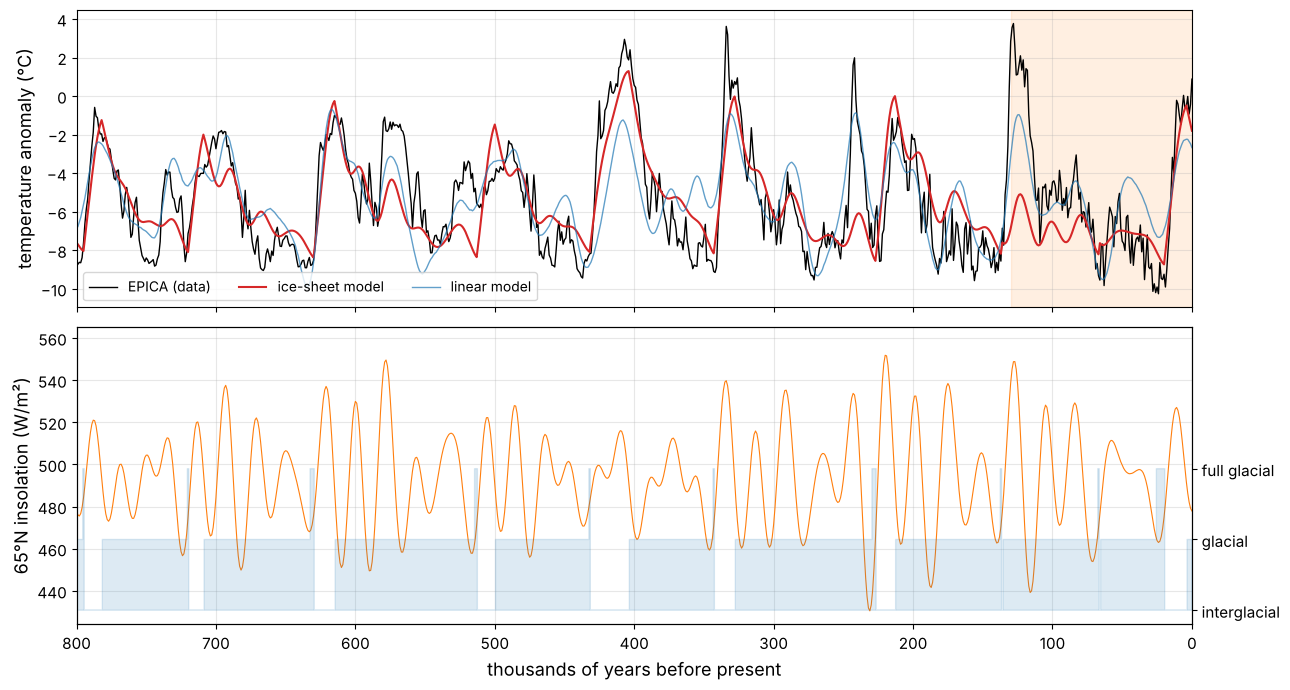

In [25]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
full_ages = climate[["age_kyr"]]
axes[0].plot(climate["age_kyr"], climate["temperature"], "k-", lw=1, label="EPICA (data)")
axes[0].plot(climate["age_kyr"], final_model.predict(full_ages), "tab:red", lw=1.5, label="ice-sheet model")
axes[0].plot(climate["age_kyr"], lin_model.predict(full_ages), "tab:blue", lw=1, alpha=0.7, label="linear model")
axes[0].axvspan(0, TEST_AGE, color="tab:orange", alpha=0.12)
axes[0].set_ylabel("temperature anomaly (°C)"); axes[0].legend(loc="lower left", ncol=3); axes[0].grid(alpha=0.3)
t_sim, V, S = final_model.simulate()
axes[1].plot(-t_sim, orbit.set_index("t_kyr").loc[t_sim, "insolation_65N"].values, "tab:orange", lw=0.8)
ax2 = axes[1].twinx()
ax2.fill_between(-t_sim, 0, S, step="mid", color="tab:blue", alpha=0.15)
ax2.set_yticks([0, 1, 2], ["interglacial", "glacial", "full glacial"]); ax2.set_ylim(-0.2, 4)
axes[1].set_ylabel("65°N insolation (W/m²)")
axes[1].set_xlim(800, 0); axes[1].set_xlabel("thousands of years before present"); axes[1].grid(alpha=0.3)
save_fig("model_fit_plot")
plt.show()

In [26]:
# When does the model end an ice age? (G -> i transitions) vs. the data (fast warmings)
model_terms = -t_sim[1:][(S[:-1] == 2) & (S[1:] == 0)]
model_terms = np.sort(model_terms[model_terms <= 800])
smooth = pd.Series(climate["temperature"].values).rolling(5, center=True).mean().values
warming = smooth[:-8] - smooth[8:]               # warming over the following 8 kyr
cand, _ = find_peaks(np.nan_to_num(warming), height=4, distance=50)
data_terms = np.sort(climate["age_kyr"].values[cand] + 4)
pairs = []
for d in data_terms:
    m = model_terms[np.argmin(np.abs(model_terms - d))]
    pairs.append({"data (kyr ago)": d, "nearest model termination": m, "difference (kyr)": m - d})
print("model terminations:", model_terms.astype(int))
pd.DataFrame(pairs)

model terminations: [ 19  66 136 226 342 431 512 629 719 794]


,data (kyr ago),nearest model termination,difference (kyr)
0,15,19.0,4.0
1,133,136.0,3.0
2,247,226.0,-21.0
3,338,342.0,4.0
4,429,431.0,2.0
5,627,629.0,2.0
6,739,719.0,-20.0
7,792,794.0,2.0


## Evaluate Your System on the Test Set

In [27]:
X_test, y_test = test_set[["age_kyr"]], test_set["temperature"].values
for name, model in [("linear", lin_model), ("gradient boosting", gbm), ("ice-sheet model", final_model)]:
    p = model.predict(X_test)
    print(f"{name:18s} test RMSE {np.sqrt(mean_squared_error(y_test, p)):.2f} °C, "
          f"correlation {np.corrcoef(p, y_test)[0, 1]:.2f}")

linear             test RMSE 2.14 °C, correlation 0.81
gradient boosting  test RMSE 2.21 °C, correlation 0.77
ice-sheet model    test RMSE 2.84 °C, correlation 0.69


In [28]:
p_model = periodogram(climate["age_kyr"].values, final_model.predict(full_ages), periods)
pd.DataFrame({"data": [band(p_obs, 19, 25), band(p_obs, 38, 44), band(p_obs, 80, 130)],
              "linear model": [band(p_lin, 19, 25), band(p_lin, 38, 44), band(p_lin, 80, 130)],
              "ice-sheet model": [band(p_model, 19, 25), band(p_model, 38, 44), band(p_model, 80, 130)]},
             index=["~23 kyr", "~41 kyr", "~100 kyr"]).round(3)

,data,linear model,ice-sheet model
~23 kyr,0.035,0.036,0.057
~41 kyr,0.186,0.386,0.127
~100 kyr,0.304,0.288,0.328


## Launch, Monitor, and Maintain Your System

Saving figure forecast_plot


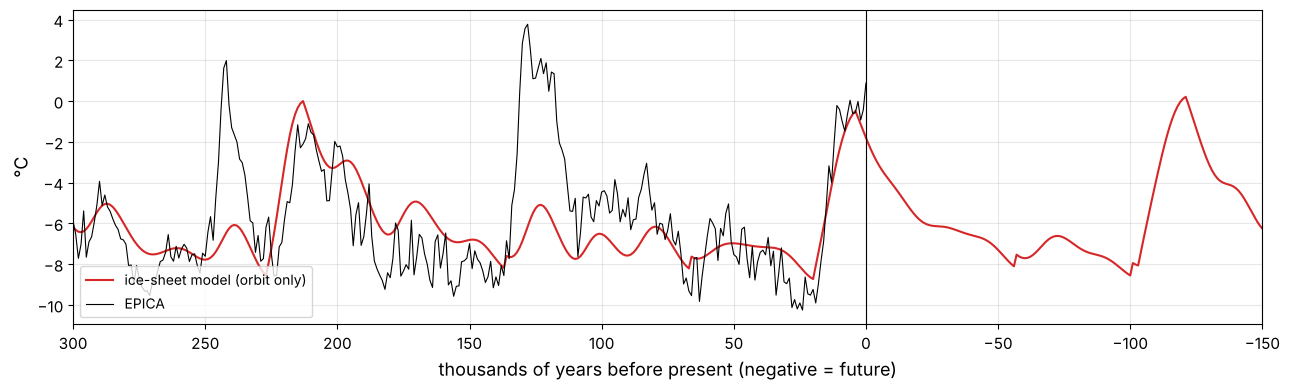

model state today: glacial
next full-glacial state in the orbit-only model: 56 kyr from now


In [29]:
t_f, V_f, S_f = final_model.simulate(until_kyr=150)
fut = t_f > 0
future_temp = final_model.a_ + final_model.b_ * V_f
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(-t_f, future_temp, "tab:red", label="ice-sheet model (orbit only)")
ax.plot(climate["age_kyr"], climate["temperature"], "k-", lw=0.8, label="EPICA")
ax.axvline(0, color="k", lw=0.8); ax.set_xlim(300, -150)
ax.set_xlabel("thousands of years before present (negative = future)"); ax.set_ylabel("°C")
ax.grid(alpha=0.3); ax.legend(loc="lower left")
save_fig("forecast_plot")
plt.show()
print("model state today:", ["interglacial", "glacial", "full glacial"][S_f[t_f == 0][0]])
next_full = t_f[fut][S_f[fut] == 2]
print(f"next full-glacial state in the orbit-only model: {next_full[0]:.0f} kyr from now" if len(next_full) else "no full glacial in the next 150 kyr")

1.25–2.5 million years ago: strongest period 41 kyr


0–1 million years ago: strongest period 96 kyr


Saving figure mid_pleistocene_transition_plot


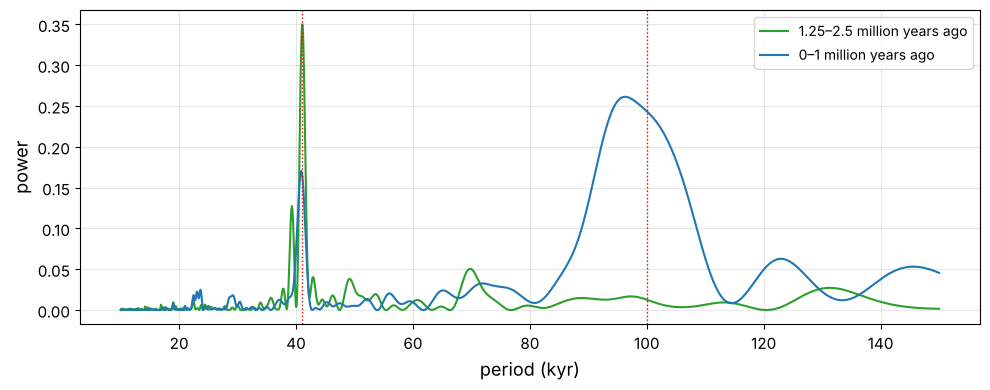

In [30]:
# Concept drift: is the 100-kyr world the only one? Periodogram of LR04 in two windows
windows = {"1.25–2.5 million years ago": (1250, 2500), "0–1 million years ago": (0, 1000)}
fig, ax = plt.subplots(figsize=(10, 4))
for (label, (lo, hi)), color in zip(windows.items(), ["tab:green", "tab:blue"]):
    w = lr04[(lr04["age_kyr"] >= lo) & (lr04["age_kyr"] <= hi)]
    pw = periodogram(w["age_kyr"].values, w["d18O"].values, periods)
    ax.plot(periods, pw, color=color, label=label)
    print(f"{label}: strongest period {periods[np.argmax(pw)]:.0f} kyr")
for p in (41, 100):
    ax.axvline(p, color="r", ls=":", lw=1)
ax.set_xlabel("period (kyr)"); ax.set_ylabel("power"); ax.legend(); ax.grid(alpha=0.3)
save_fig("mid_pleistocene_transition_plot")
plt.show()

In [31]:
pre_industrial = co2[(co2["age_kyr"] >= 2) & (co2["age_kyr"] <= 800)]
print(f"CO2 in the training period: {pre_industrial['co2_ppm'].min():.0f}–"
      f"{pre_industrial['co2_ppm'].max():.0f} ppm;  today: ≈420 ppm")

CO2 in the training period: 174–299 ppm;  today: ≈420 ppm


In [32]:
import json
os.makedirs("animations", exist_ok=True)
t_a, V_a, S_a = final_model.simulate(until_kyr=100)
keep = t_a >= -800
anim = {"t": t_a[keep].tolist(), "ice": V_a[keep].round(4).tolist(), "state": S_a[keep].tolist(),
        "ins": orbit.set_index("t_kyr").loc[t_a[keep], "insolation_65N"].round(2).tolist(),
        "ecc": orbit.set_index("t_kyr").loc[t_a[keep], "ecc"].round(5).tolist(),
        "obl": np.degrees(orbit.set_index("t_kyr").loc[t_a[keep], "obliquity"]).round(4).tolist(),
        "varpi": np.degrees(orbit.set_index("t_kyr").loc[t_a[keep], "varpi"]).round(3).tolist(),
        "temp_obs": np.interp(-t_a[keep], climate["age_kyr"], climate["temperature"], right=np.nan).round(2).tolist(),
        "a": float(final_model.a_), "b": float(final_model.b_)}
anim["temp_obs"] = [None if np.isnan(v) else v for v in anim["temp_obs"]]
with open(os.path.join("animations", "fitted_parameters.json"), "w") as f:
    json.dump(anim, f)
print(len(anim["t"]), "time steps exported")

901 time steps exported
